<a href="https://colab.research.google.com/github/Gloou-ui/NM/blob/main/%D0%9B%D0%B8%D1%82%D0%B2%D0%B8%D0%BD_%D0%A4%D0%86%D0%A23_10_%D0%9B%D0%A010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Розпізнавання дорожніх знаків за допомогою CNN

Мета роботи — побудувати згорткову нейронну мережу (CNN), яка класифікує зображення дорожніх знаків на 43 класи.


## 1. Імпорт бібліотек

In [1]:
import os, zipfile, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


## 2. Завантаження набору даних безпосередньо з Kaggle

Використовуємо бібліотеку `kagglehub`. Вона завантажує файли публічного набору даних із вказаної сторінки Kaggle прямо в середовище Google Colab. Жодних локальних файлів користувача для цього кроку не потрібно.

In [2]:
!pip -q install kagglehub

import kagglehub
import os
import pathlib

DATA_DIR = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

print("Набір даних завантажено з Kaggle.")
print("Шлях до даних:", DATA_DIR)

for root, dirs, files_ in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for filename in files_[:5]:
            print("  " * (level + 1) + filename)


Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Набір даних завантажено з Kaggle.
Шлях до даних: /kaggle/input/gtsrb-german-traffic-sign
gtsrb-german-traffic-sign/
  Meta.csv
  Train.csv
  Test.csv
  Meta/
    37.png
    35.png
    11.png
    31.png
    4.png
  meta/
    37.png
    35.png
    11.png
    31.png
    4.png
  Test/
    01301.png
    02578.png
    06781.png
    11396.png
    00929.png
  test/
    01301.png
    02578.png
    06781.png
    11396.png
    00929.png
  Train/
    7/
      00007_00041_00020.png
      00007_00021_00024.png
      00007_00027_00000.png
      00007_00038_00003.png
      00007_00001_00024.png
    17/
      00017_00013_00010.png
      00017_00003_00027.png
      00017_00006_00018.png
      00017_00035_00013.png
      00017_00000_00018.png
    19/
      00019_00002_00015.png
      00019_00006_00028.png
      00019_00005_00013.png
      00019_00003_00026.png
      00019_00005_00016.png
    22/
      00022_00009_00013.png
  

## 3. Пошук папки з навчальними зображеннями

У наборі GTSRB навчальні зображення зазвичай розміщені в папці `Train` (або `train`), а всередині неї є 43 папки з номерами класів від 0 до 42. Знайдемо цю папку автоматично, щоб код не залежав від точного шляху після завантаження.

In [3]:
candidates = []

for root, dirs, files_ in os.walk(DATA_DIR):
    numeric_dirs = {
        int(d) for d in dirs
        if d.isdigit() and 0 <= int(d) < 43
    }
    if len(numeric_dirs) == 43:
        candidates.append(root)

if not candidates:
    raise FileNotFoundError(
        "Не вдалося знайти папку з 43 класами (0–42). "
        "Перевірте структуру завантаженого набору Kaggle."
    )

TRAIN_DIR = min(candidates, key=len)

print("Папка навчальних зображень:", TRAIN_DIR)
print("Кількість класів:", len([
    d for d in os.listdir(TRAIN_DIR)
    if d.isdigit() and 0 <= int(d) < 43
]))


Папка навчальних зображень: /kaggle/input/gtsrb-german-traffic-sign/Train
Кількість класів: 43


## 4. Підготовка даних

Для подачі в нейронну мережу всі зображення приводяться до розміру 32×32 пікселі. Навчальна папка автоматично поділяється на дві частини: 80% зображень для навчання та 20% для перевірки якості моделі. Для перевірочної вибірки вимикаємо перемішування, щоб правильно зіставляти справжні та прогнозовані класи під час оцінювання.

In [4]:
IMG_SIZE = (32, 32)
BATCH_SIZE = 128
NUM_CLASSES = 43
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    class_names=[str(i) for i in range(NUM_CLASSES)],
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="int",
    class_names=[str(i) for i in range(NUM_CLASSES)],
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Кількість класів:", len(class_names))
print("Назви класів:", class_names)


Found 39209 files belonging to 43 classes.
Using 31368 files for training.
Found 39209 files belonging to 43 classes.
Using 7841 files for validation.
Кількість класів: 43
Назви класів: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42']


## 5. Виведення прикладів зображень

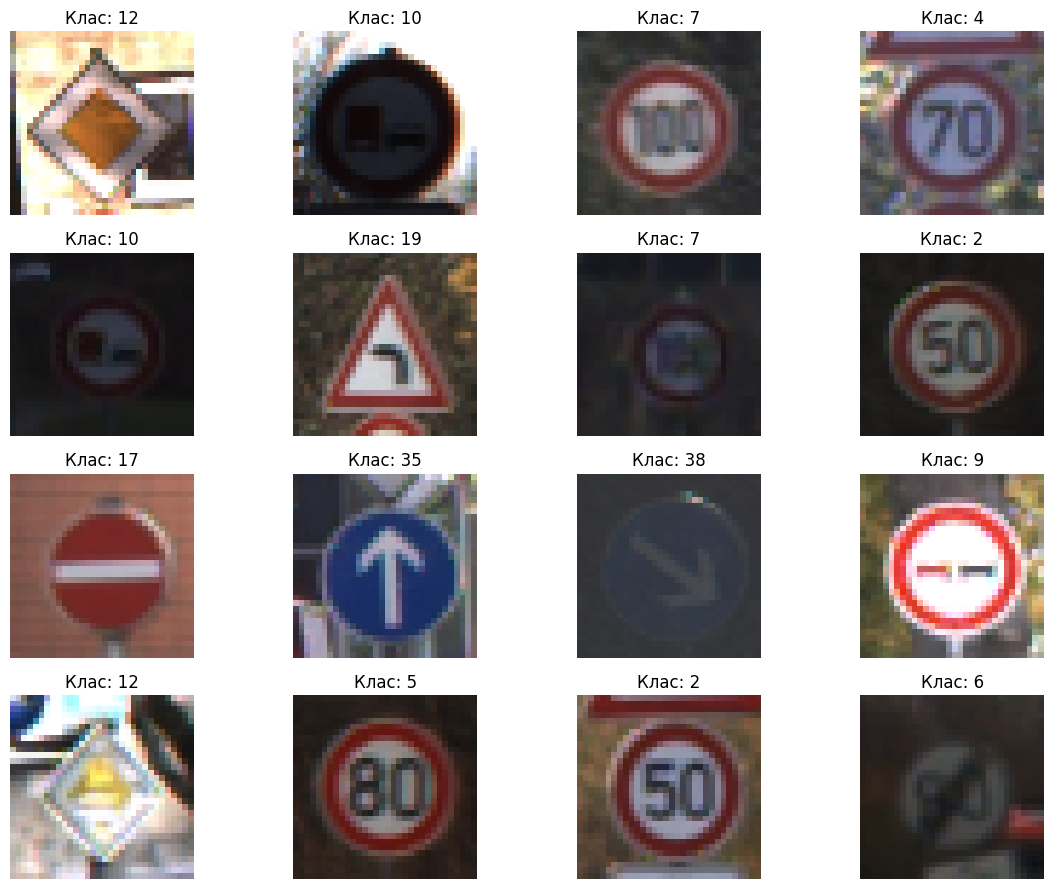

In [5]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(12, 9))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"Клас: {int(labels[i])}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Побудова архітектури CNN

Модель складається з трьох згорткових блоків `Conv2D`, пакетної нормалізації `BatchNormalization`, зменшення розмірності `MaxPooling2D` та регуляризації `Dropout`. Вихідний шар має 43 нейрони — по одному для кожного класу дорожніх знаків. `Rescaling` нормалізує пікселі до діапазону 0–1.

In [6]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.08, 0.08)
])

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Rescaling(1./255),
    augmentation,

    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.40),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 676,939 (2.58 MB)

 Trainable params: 675,979 (2.58 MB)

 Non-trainable params: 960 (3.75 KB)

## 7. Навчання моделі

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    )
]
history = model.fit(
    train_ds, validation_data=val_ds,
    epochs=20, callbacks=callbacks
)

Epoch 1/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 157s 624ms/step - accuracy: 0.3638 - loss: 2.3484 - val_accuracy: 0.2848 - val_loss: 3.4593 - learning_rate: 0.0010
Epoch 2/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 211s 662ms/step - accuracy: 0.7163 - loss: 0.8868 - val_accuracy: 0.7173 - val_loss: 1.0148 - learning_rate: 0.0010
Epoch 3/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 160s 650ms/step - accuracy: 0.8497 - loss: 0.4717 - val_accuracy: 0.9538 - val_loss: 0.1794 - learning_rate: 0.0010
Epoch 4/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 191s 606ms/step - accuracy: 0.9126 - loss: 0.2795 - val_accuracy: 0.8948 - val_loss: 0.3376 - learning_rate: 0.0010
Epoch 5/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 197s 801ms/step - accuracy: 0.9376 - loss: 0.2031 - val_accuracy: 0.9834 - val_loss: 0.0674 - learning_rate: 0.0010
Epoch 6/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 169s 666ms/step - accuracy: 0.9579 - loss: 0.1375 - val_accuracy: 0.9921 - val_loss: 0.0352 - learning_rate: 0.0010
Epoch 7/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 196s 641ms/step - accura

## 8. Криві навчання

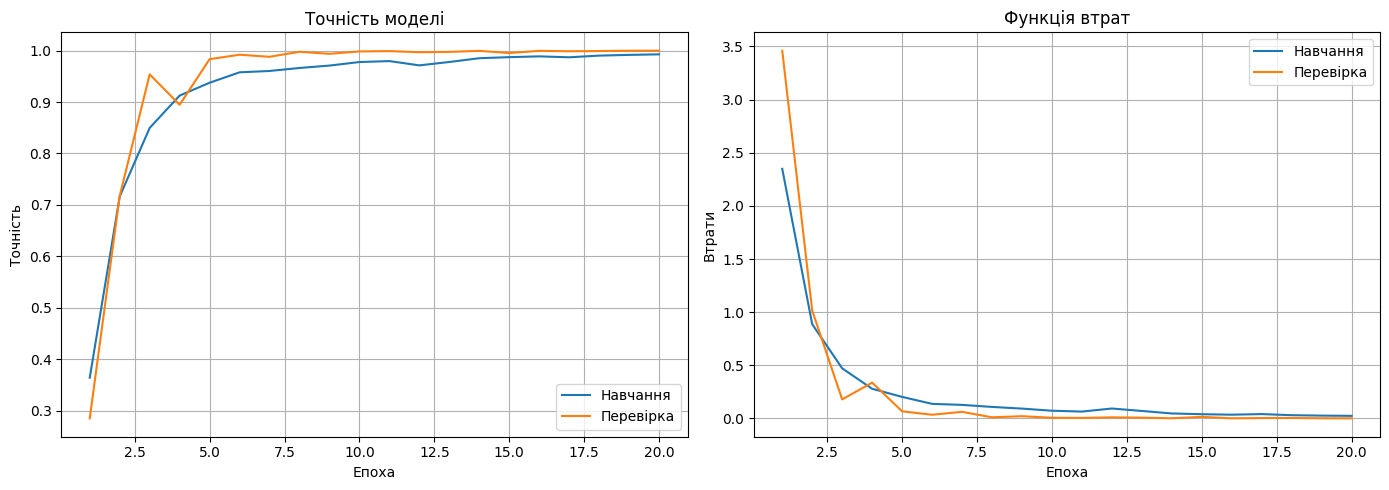

In [8]:
ep = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(ep, history.history["accuracy"], label="Навчання")
plt.plot(ep, history.history["val_accuracy"], label="Перевірка")
plt.xlabel("Епоха"); plt.ylabel("Точність")
plt.title("Точність моделі"); plt.legend(); plt.grid()

plt.subplot(1, 2, 2)
plt.plot(ep, history.history["loss"], label="Навчання")
plt.plot(ep, history.history["val_loss"], label="Перевірка")
plt.xlabel("Епоха"); plt.ylabel("Втрати")
plt.title("Функція втрат"); plt.legend(); plt.grid()

plt.tight_layout()
plt.show()

## 9. Оцінювання моделі

In [9]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
print(f"Втрати на перевірочній вибірці: {val_loss:.4f}")
print(f"Точність на перевірочній вибірці: {val_accuracy:.2%}")

Втрати на перевірочній вибірці: 0.0013
Точність на перевірочній вибірці: 99.99%


## 10. Звіт класифікації та матриця помилок

Звіт містить метрики precision, recall і F1-score для кожного класу. Матриця помилок показує, які класи модель найчастіше плутає.

              precision    recall  f1-score   support

      Клас 0       0.00      0.00      0.00         0
      Клас 1       0.00      0.00      0.00         0
      Клас 2       0.00      0.00      0.00         0
      Клас 3       0.00      0.00      0.00         0
      Клас 4       0.00      0.00      0.00         0
      Клас 5       0.00      0.00      0.00         0
      Клас 6       0.00      0.00      0.00         0
      Клас 7       0.00      0.00      0.00         0
      Клас 8       0.00      0.00      0.00         0
      Клас 9       0.00      0.00      0.00         0
     Клас 10       0.00      0.00      0.00         0
     Клас 11       0.00      0.00      0.00         0
     Клас 12       0.00      0.00      0.00         0
     Клас 13       0.00      0.00      0.00         0
     Клас 14       0.00      0.00      0.00         0
     Клас 15       0.00      0.00      0.00         0
     Клас 16       0.00      0.00      0.00         0
     Клас 17       0.00    

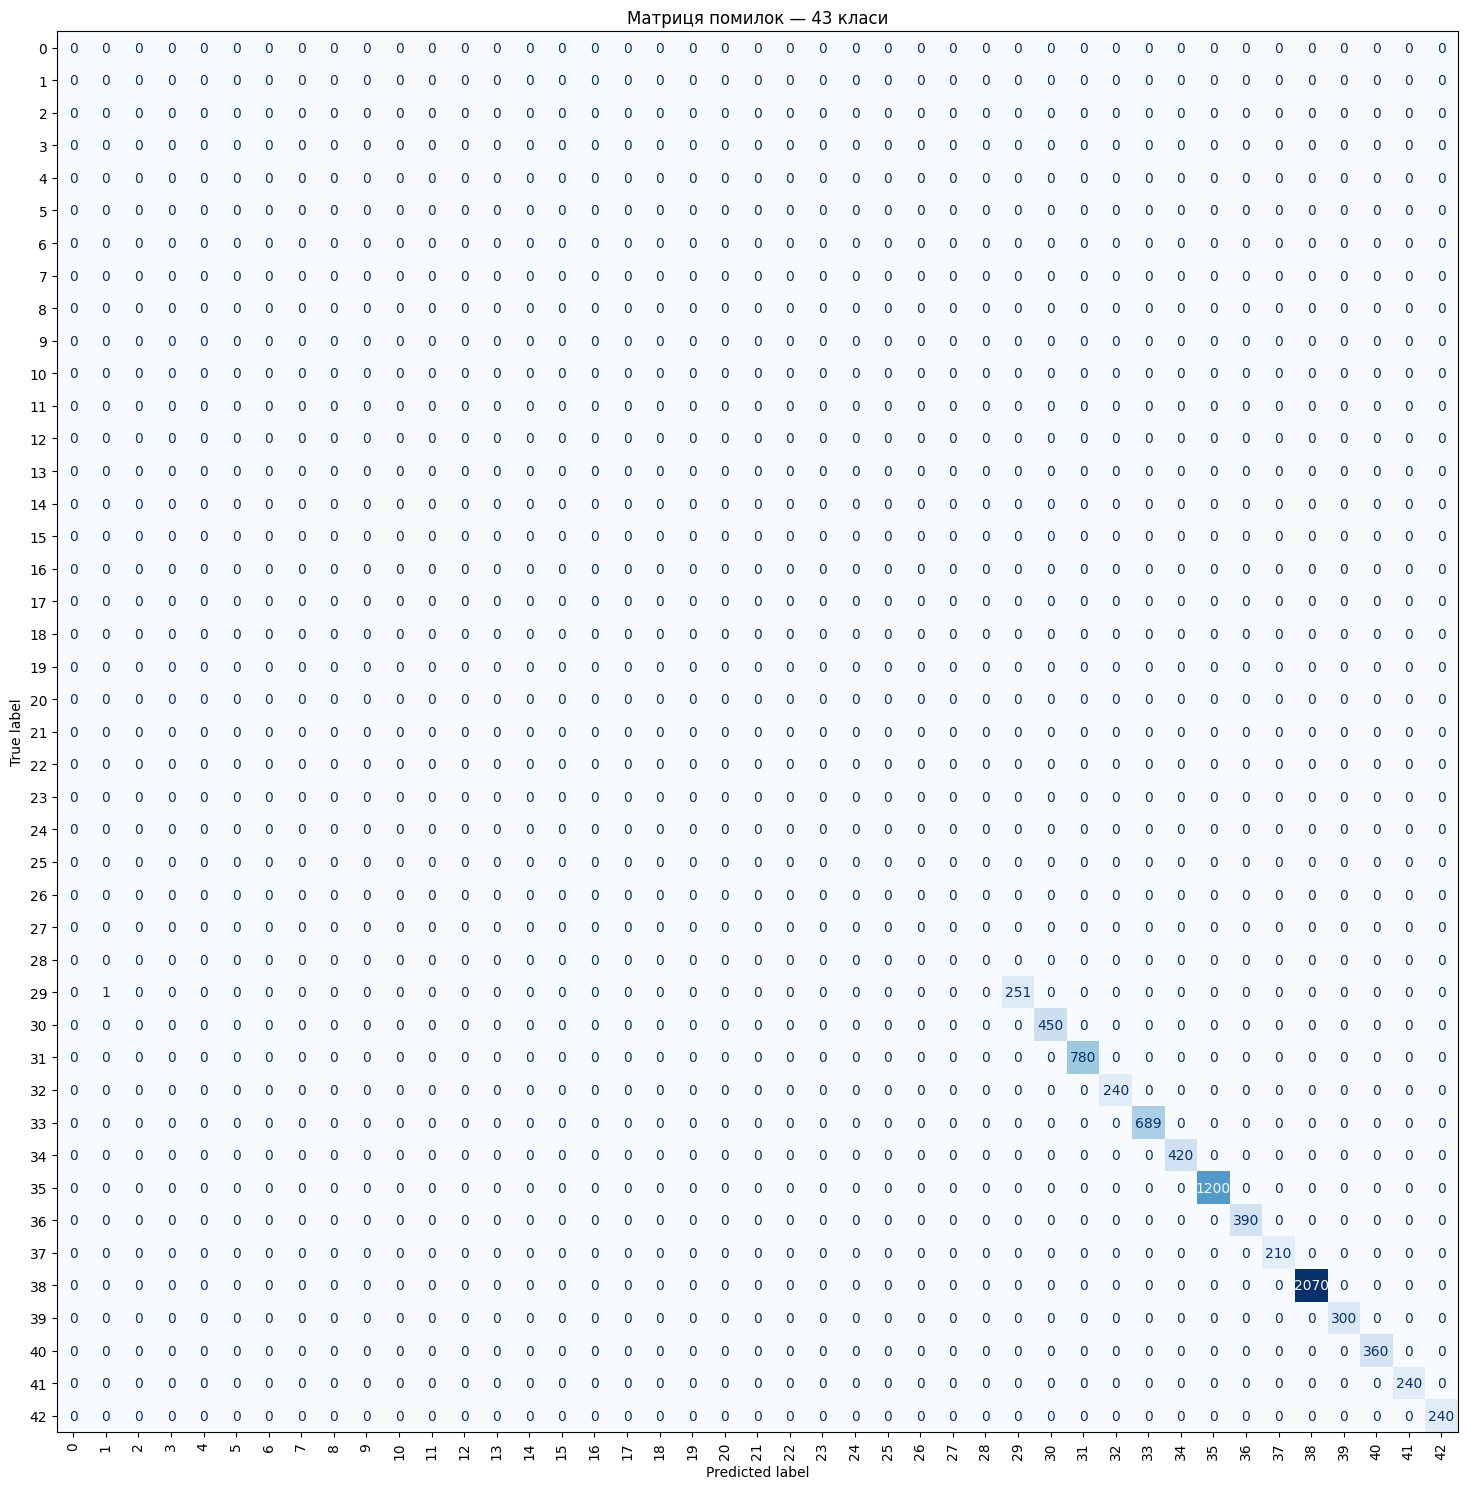

In [10]:
y_true = np.concatenate([y.numpy() for x, y in val_ds])
y_prob = model.predict(val_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true, y_pred, labels=np.arange(NUM_CLASSES),
    target_names=[f"Клас {i}" for i in range(NUM_CLASSES)],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(15, 15))
ConfusionMatrixDisplay(cm, display_labels=np.arange(NUM_CLASSES)).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation="vertical"
)
plt.title("Матриця помилок — 43 класи")
plt.tight_layout()
plt.show()

## 11. Візуалізація класифікації: зображення, справжній і прогнозований клас

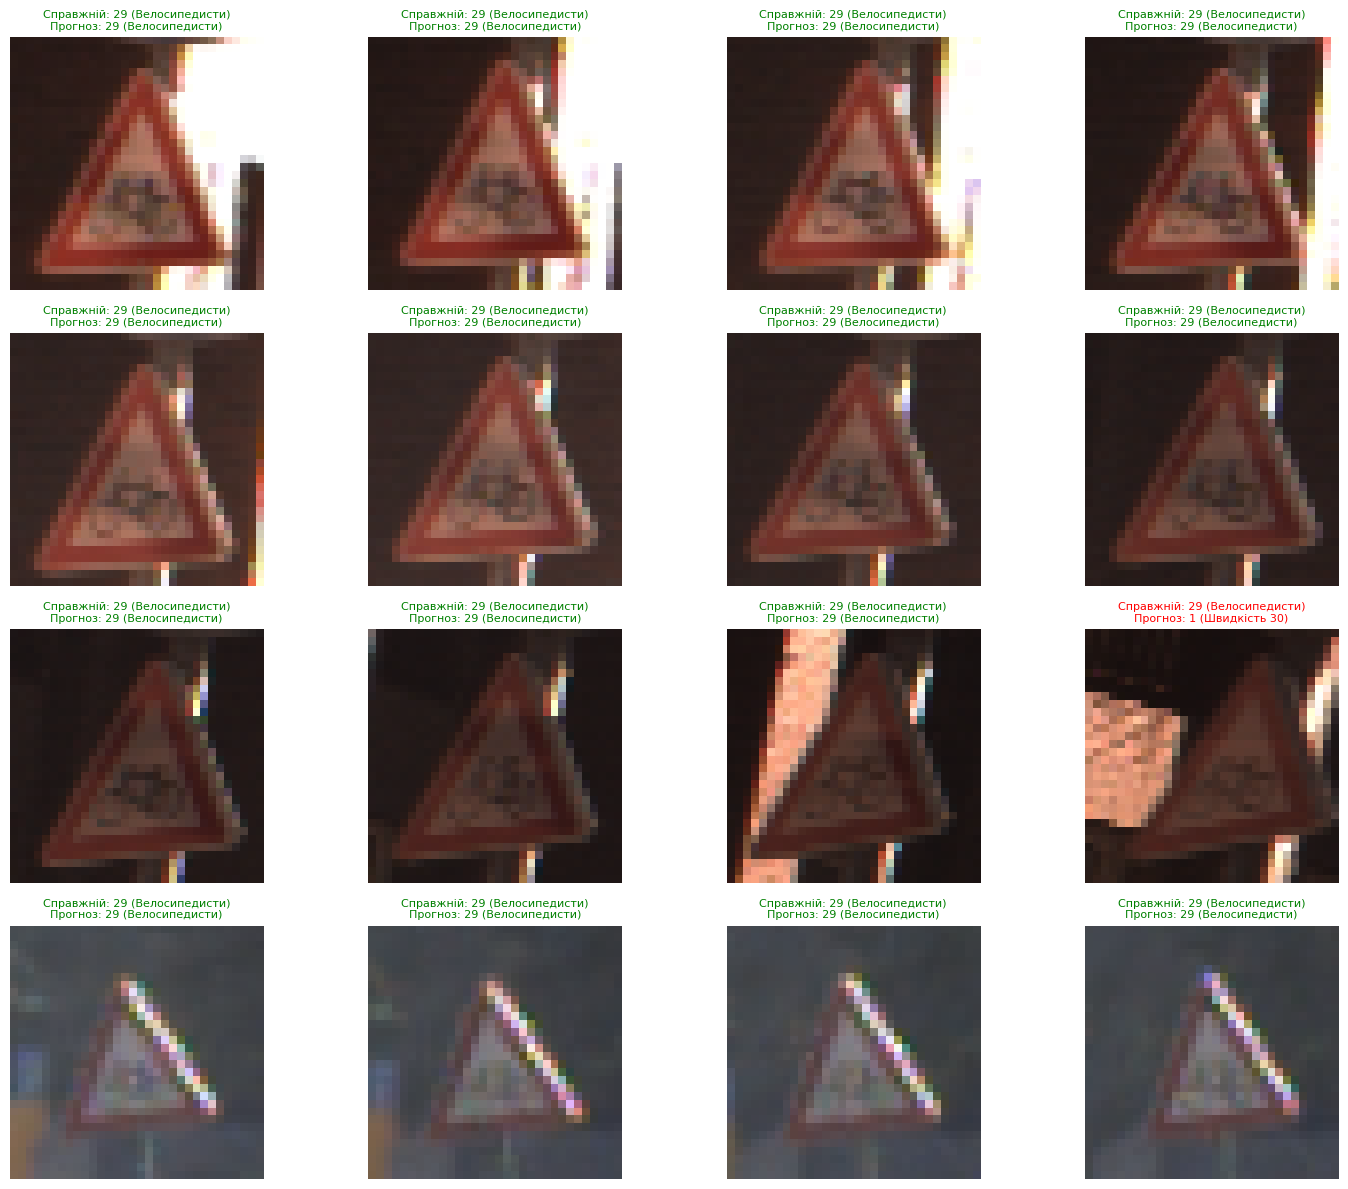

In [11]:
class_labels_uk = {
    0:"Швидкість 20", 1:"Швидкість 30", 2:"Швидкість 50",
    3:"Швидкість 60", 4:"Швидкість 70", 5:"Швидкість 80",
    6:"Кінець обмеження 80", 7:"Швидкість 100", 8:"Швидкість 120",
    9:"Обгін заборонено", 10:"Обгін вантажівкам заборонено",
    11:"Перехрестя з другорядною дорогою", 12:"Головна дорога",
    13:"Дати дорогу", 14:"STOP", 15:"Рух заборонено",
    16:"Вантажівкам заборонено", 17:"В'їзд заборонено",
    18:"Інша небезпека", 19:"Поворот ліворуч", 20:"Поворот праворуч",
    21:"Подвійний поворот", 22:"Нерівна дорога", 23:"Слизька дорога",
    24:"Звуження дороги", 25:"Дорожні роботи", 26:"Світлофор",
    27:"Пішохідний перехід", 28:"Діти", 29:"Велосипедисти",
    30:"Ожеледиця", 31:"Дикі тварини", 32:"Кінець обмежень",
    33:"Рух праворуч", 34:"Рух ліворуч", 35:"Рух прямо",
    36:"Прямо або праворуч", 37:"Прямо або ліворуч",
    38:"Об'їзд праворуч", 39:"Об'їзд ліворуч",
    40:"Кільцевий рух", 41:"Кінець заборони обгону",
    42:"Кінець заборони обгону вантажівкам"
}

images, true_labels = next(iter(val_ds))
probs = model.predict(images, verbose=0)
pred_labels = np.argmax(probs, axis=1)

plt.figure(figsize=(15, 12))
for i in range(min(16, len(images))):
    true_id = int(true_labels[i])
    pred_id = int(pred_labels[i])
    plt.subplot(4, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    color = "green" if true_id == pred_id else "red"
    plt.title(
        f"Справжній: {true_id} ({class_labels_uk[true_id]})\n"
        f"Прогноз: {pred_id} ({class_labels_uk[pred_id]})",
        color=color, fontsize=8
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 12. Приклади помилкових прогнозів

Кількість помилок: 1


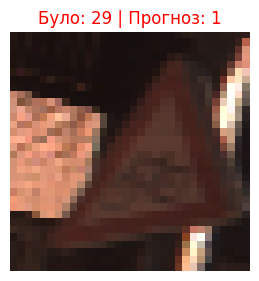

In [12]:
wrong = np.where(y_true != y_pred)[0]
print("Кількість помилок:", len(wrong))

if len(wrong):
    wrong_ds = val_ds.unbatch().skip(int(wrong[0])).take(1)
    plt.figure(figsize=(14, 8))
    for j, idx in enumerate(wrong[:12]):
        img, true_id = list(val_ds.unbatch().skip(int(idx)).take(1))[0]
        pred_id = int(y_pred[idx])
        plt.subplot(3, 4, j + 1)
        plt.imshow(img.numpy().astype("uint8"))
        plt.title(f"Було: {int(true_id)} | Прогноз: {pred_id}", color="red")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Помилкових прогнозів на перевірочній вибірці немає.")

## 13. Збереження моделі

In [13]:
model.save("/content/gtsrb_cnn_model.keras")
print("Модель збережено у файл /content/gtsrb_cnn_model.keras")

Модель збережено у файл /content/gtsrb_cnn_model.keras


## 14. Висновок

  Ми навчились зтворювати згордкову нейро мережу для розпізнавання дорожніх знаків із набору даних GTSRB. Дані було завантажено безпосередньо з ресурсу Kaggle за допомогою бібліотеки kagglehub.

  Зображення конверктувались до однакового розміру 32×32 пікселі та поділено на навчальну і перевірочну вибірки зображень. Для класифікації використано згорткові шари Conv2D, пакетну нормалізацію BatchNormalization, шари зменшення розмірності MaxPooling2D та регуляризацію Dropout.

Після навчання, робиться графіки точності та функції втрат для навчальної й перевірочної вибірок, сама модель при навчанні потребувала досить багато часу, це зайняло приблизно годину.
